# Experiment: MATF-GAN-inspired (LOOSE)

LOOSE VERSION of MATF-GAN (Zhao et al., CVPR 2019; 4.13 m at 5 s in BAT's table). MATF places every agent's encoding into a spatial tensor at its location, fuses the tensor with convolutions, reads each agent's fused vector back out, and decodes; the GAN version adds a discriminator. Details beyond that were not checked, so this is a loose reconstruction.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | LOOSE VERSION: not enough public detail to reproduce this model; the architecture below is our interpretation of its title/abstract. Results do NOT represent the published model. | User asked for best-effort versions of thin-detail models. | Treat as an extra baseline, not as a reproduction. |
| M2 | Multi-agent tensor: every real vehicle (target included) placed on the 13 x 3 grid at its longitudinal cell and relative lane. | MATF's spatial alignment of agent encodings. | MATF also fuses a scene (map) image; NGSIM has none here. |
| M3 | Fusion: small U-Net (conv 3x3 64 -> down 2x1 -> conv 128 -> up -> skip concat -> conv 64); the target's fused vector is read at the centre cell and concatenated with its own encoding. | MATF's convolutional fusion. | - |
| M4 | Generator / discriminator as `s_gan`. | MATF-GAN's adversarial variant. | - |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "matf_gan"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "LOOSE: multi-agent tensor fusion (agent encodings on a spatial grid, U-Net fusion) + GAN"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-29 19:22:29,800 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-29 19:22:37,041 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-29 19:22:37,838 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-29 19:22:37,863 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-29 19:22:37,896 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-29 19:40:28,450 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-29 19:41:02,278 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/matf_gan/intention_clusters.pkl


2026-10-29 19:41:03,832 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** multi-agent tensor (M2), U-Net fusion (M3), GAN parts as `s_gan` (M4). Built after the data cell because it needs `norm_stats`.

In [4]:
def moment_match(raw, weights):
    """(B, M, T, 5) raw mode outputs + (B, M) mode weights -> (B, T, 5) one Gaussian (S7)."""
    mu = raw[..., :2]
    sig = F.softplus(raw[..., 2:4]) + 1e-3
    rho = torch.tanh(raw[..., 4])
    w = weights[:, :, None]                                         # (B, M, 1)
    mean = (w[..., None] * mu).sum(1)                               # (B, T, 2)
    d = mu - mean[:, None]
    var = (w[..., None] * (sig ** 2 + d ** 2)).sum(1)
    cov = (w * (rho * sig[..., 0] * sig[..., 1] + d[..., 0] * d[..., 1])).sum(1)
    sx, sy = var[..., 0].sqrt(), var[..., 1].sqrt()
    return torch.stack([mean[..., 0], mean[..., 1], sx, sy, (cov / (sx * sy)).clamp(-0.999, 0.999)], dim=-1)

class VehicleEncoder(nn.Module):
    """Shared per-vehicle encoder: FC + leaky ReLU + LSTM over the 30 history steps."""
    def __init__(self, input_dim=STATE_DIM, emb=32, d=64):
        super().__init__()
        self.embed = nn.Linear(input_dim, emb)
        self.lstm = nn.LSTM(emb, d, batch_first=True)

    def forward(self, x):                                           # x (B, T, N, F)
        B, T, N, D_in = x.shape
        seq, (h, _) = self.lstm(F.leaky_relu(self.embed(x.transpose(1, 2).reshape(B * N, T, D_in)), 0.1))
        return seq.reshape(B, N, T, -1), h[-1].reshape(B, N, -1)   # per-step and last-step encodings

def social_grid(raw_last, mask, h, rows=13, cols=3, cell=4.572):
    """Scatter neighbour vectors h (B, N, C) into a (B, C, rows, cols) grid by longitudinal offset
    (feature 0) and relative lane (feature 6, left = +) at the last step; the target is left out."""
    B, N, C = h.shape
    row = torch.floor(raw_last[..., 0] / cell + rows / 2).long()
    col = (cols // 2 - torch.round(raw_last[..., 6])).long()
    inside = mask & (row >= 0) & (row < rows) & (col >= 0) & (col < cols)
    inside[:, 0] = False
    b, v = inside.nonzero(as_tuple=True)
    grid = h.new_zeros(B, rows * cols, C)
    grid[b, row[b, v] * cols + col[b, v]] = h[b, v]                 # two vehicles in one cell: the later one wins
    return grid.view(B, rows, cols, C).permute(0, 3, 1, 2)

from torch.func import functional_call


class TrajDiscriminator(nn.Module):
    """Scores a future trajectory (B, T_f, 2) given the scene context (B, C): real vs generated."""
    def __init__(self, ctx, d=64):
        super().__init__()
        self.embed = nn.Linear(2, d)
        self.lstm = nn.LSTM(d, d, batch_first=True)
        self.head = nn.Sequential(nn.Linear(d + ctx, d), nn.LeakyReLU(0.2), nn.Linear(d, 1))

    def forward(self, traj, ctx):
        steps = torch.diff(traj, dim=1, prepend=torch.zeros_like(traj[:, :1]))   # metres per step
        _, (h, _) = self.lstm(F.leaky_relu(self.embed(steps), 0.2))
        return self.head(torch.cat([h[-1], ctx], dim=-1)).squeeze(-1)


def gan_losses(disc, real, fake, ctx):
    """Discriminator loss on detached inputs + generator loss through a frozen copy of the
    discriminator, so one optimizer step trains each player only on its own objective."""
    bce = F.binary_cross_entropy_with_logits
    d_real, d_fake = disc(real, ctx.detach()), disc(fake.detach(), ctx.detach())
    loss_d = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
    frozen = {k: v.detach() for k, v in disc.named_parameters()}
    g = functional_call(disc, frozen, (fake, ctx))
    return loss_d + bce(g, torch.ones_like(g))


def sample_mean(generate, ctx, n_samples, noise_dim, seed=SEED):
    """n fixed-seed samples of generate(ctx, z) -> raw (B, T, 5), moment-matched with equal weights (S7)."""
    g = torch.Generator(device=ctx.device).manual_seed(seed)
    B = ctx.shape[0]
    z = torch.randn(B * n_samples, noise_dim, generator=g, device=ctx.device)
    raw = generate(ctx.repeat_interleave(n_samples, dim=0), z).reshape(B, n_samples, TF_STEPS, 5)
    return moment_match(raw, ctx.new_full((B, n_samples), 1.0 / n_samples))

class MATFGAN(nn.Module):
    def __init__(self, norm_stats, d=64, noise=8, dec=128, n_samples=20, T_f=TF_STEPS):
        super().__init__()
        self.register_buffer("mean", torch.tensor(norm_stats["mean"]))
        self.register_buffer("std", torch.tensor(norm_stats["std"]))
        self.noise, self.n_samples, self.T_f = noise, n_samples, T_f
        self.encoder = VehicleEncoder(STATE_DIM, 32, d)
        self.down1 = nn.Conv2d(d, 64, 3, padding=1)
        self.down2 = nn.Conv2d(64, 128, 3, padding=1)
        self.up = nn.ConvTranspose2d(128, 64, (2, 1), stride=(2, 1))
        self.fuse = nn.Conv2d(128, d, 3, padding=1)
        self.decoder = nn.LSTM(2 * d + noise, dec, batch_first=True)
        self.out = nn.Linear(dec, 5)
        self.disc = TrajDiscriminator(2 * d)

    def context(self, states, mask):
        _, h = self.encoder(states)
        grid = social_grid(states[:, -1] * self.std + self.mean, mask, h)   # neighbours
        grid[:, :, 6, 1] = h[:, 0]                                  # M2: the target at the centre cell
        x1 = F.relu(self.down1(grid))                               # (B, 64, 13, 3)
        x2 = F.relu(self.down2(F.max_pool2d(x1[:, :, :12], (2, 1))))   # (B, 128, 6, 3)
        up = F.pad(self.up(x2), (0, 0, 0, 1))                       # back to (B, 64, 13, 3)
        fused = F.relu(self.fuse(torch.cat([x1, up], 1)))           # M3
        return torch.cat([h[:, 0], fused[:, :, 6, 1]], -1)

    def generate(self, ctx, z):
        out, _ = self.decoder(torch.cat([ctx, z], -1)[:, None].expand(-1, self.T_f, -1))
        return self.out(out)

    def forward(self, states, mask, dims=None):
        B, _, N, _ = states.shape
        ctx = self.context(states, mask)
        if self.training:
            raw = self.generate(ctx, torch.randn(B, self.noise, device=ctx.device))
            traj = moment_match(raw[:, None], ctx.new_ones(B, 1))
        else:
            traj = sample_mean(self.generate, ctx, self.n_samples, self.noise)
        return traj, states.new_zeros(B, N - 1, 4), None

    def aux_loss(self, states, mask, dims, gt):
        ctx = self.context(states, mask)
        fake = self.generate(ctx, torch.randn(ctx.shape[0], self.noise, device=ctx.device))[..., :2]
        return gan_losses(self.disc, gt, fake, ctx)


def build_model():
    return MATFGAN(norm_stats)

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

MATFGAN: 409,222 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-29 19:41:04,833 - STRAP - INFO - Training STRAP on cuda


2026-10-29 19:41:04,834 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-29 19:41:04,834 - STRAP - INFO - Number of training batches: 4220


2026-10-29 19:41:04,835 - STRAP - INFO - Number of validation batches: 673


2026-10-29 19:44:34,248 - STRAP - INFO - Epoch 1/12: Train Loss=674.7260 (goal=598.7885, traj=73.2779), Val Loss=393.4652, Val RMSE=2.4721


...

2026-10-29 20:15:16,964 - STRAP - INFO -   -> Saved best checkpoint (val_loss=392.5995)


2026-10-29 20:18:46,286 - STRAP - INFO - Epoch 11/12: Train Loss=608.8428 (goal=598.7891, traj=7.9590), Val Loss=392.6449, Val RMSE=2.3507


2026-10-29 20:22:12,604 - STRAP - INFO - Epoch 12/12: Train Loss=608.8309 (goal=598.7873, traj=7.9492), Val Loss=392.6326, Val RMSE=2.3481


2026-10-29 20:22:12,645 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,674.725967,598.788542,73.277883,393.465166,2.472058,0.000300
1,2,609.713457,598.788345,8.816880,393.127384,2.422651,0.000180
2,3,609.342636,598.786486,8.461565,392.899063,2.393023,0.000108
3,4,609.081637,598.788439,8.207573,392.866044,2.399061,0.000065
4,5,608.941448,598.786934,8.072453,392.674037,2.359713,0.000039
5,6,608.902594,598.785535,8.028830,392.601912,2.334236,0.000023
6,7,608.973203,598.785867,8.085814,392.694677,2.352736,0.000014
7,8,608.907752,598.786809,8.028020,392.806411,2.378598,0.000008
8,9,608.864518,598.787036,7.988269,392.700082,2.358690,0.000005
9,10,608.847448,598.787393,7.967331,392.599543,2.340618,0.000003


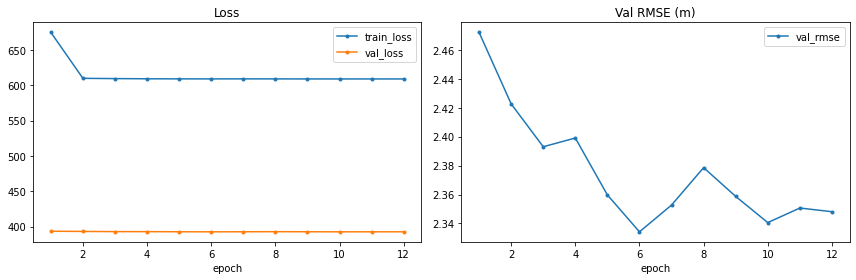

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,0.502074,1.239580,2.165080,3.361573,4.857491,2.425160,121130.0
site us-101,0.469679,1.189638,2.134009,3.409040,5.015438,2.443561,62135.0
zero-neighbour samples,0.580936,1.398516,2.419409,3.781313,5.532731,2.742581,3120.0
site i-80,0.533850,1.290071,2.197059,3.310998,4.685107,2.403417,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/matf_gan.json


PosixPath('/home/st_students/MTP/experiments/results/matf_gan.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
dacr_amtp,"LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries","us-101,i-80",12,254150,0.4603,1.1221,1.9212,2.9094,4.1144,2.1055,2.0954,2.4974,2.1150
cognitive,"Cognitive-driven: safety (TTC/TET/TIT) + behaviour centrality + priority attention, Leanformer fusion","us-101,i-80",12,227979,0.4624,1.1204,1.9247,2.9255,4.1366,2.1139,2.0999,2.5102,2.1276
inatran,LOOSE: interaction-aware spatio-temporal transformer with future-step queries,"us-101,i-80",12,173381,0.4740,1.1277,1.9305,2.9271,4.1289,2.1176,2.1055,2.5476,2.1297
gava,LOOSE (name only): gated attention + conditional VAE,"us-101,i-80",12,210757,0.4679,1.1431,1.9574,2.9665,4.1877,2.1445,2.1282,2.5460,2.1605
fhif,LOOSE: individual / pairwise / group interaction features fused hierarchically with gates,"us-101,i-80",12,171141,0.4782,1.1477,1.9584,2.9617,4.1814,2.1455,2.1451,2.5409,2.1447
hltp,"HLTP teacher: adaptive visual-sector pooling + LSTM/attention + GAT + iTransformer fusion, manoeuvre-supervised","us-101,i-80",12,232050,0.4920,1.1527,1.9621,2.9713,4.2036,2.1564,2.1293,2.5414,2.1834
gnp,GNP: attention goal predictor + learned social-force rollout towards each goal,"us-101,i-80",12,49399,0.4886,1.1634,1.9871,3.0225,4.2939,2.1911,2.1590,2.7703,2.2232
cf_lstm,"LOOSE: cascaded LSTMs (vehicle states, then target + per-step pooled interaction)","us-101,i-80",12,175109,0.4755,1.1638,2.0026,3.0541,4.3407,2.2073,2.2001,2.5426,2.2135
cs_lstm,CS-LSTM: LSTM encoders + 13x3 convolutional social pooling (unimodal),"us-101,i-80",12,192117,0.4738,1.1644,2.0267,3.1300,4.5015,2.2593,2.2737,2.5803,2.2420


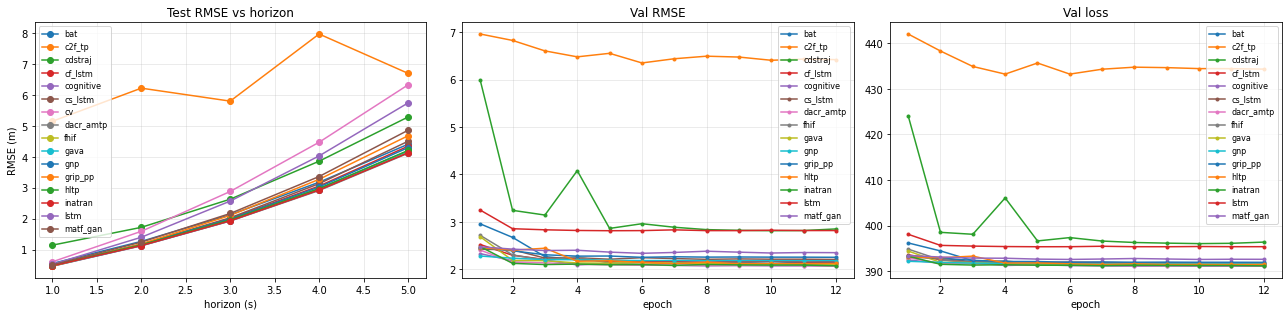

In [9]:
rmse_df, collision_df = compare()